# 1장 파이썬으로 확률을 계산하는 방법

## 1.1 표본 공간 분석 : 방정식 없이 결과의 불확실성을 측정하는 접근법

#### Code 1 - 1 동전 뒤집기에 대한 표본 공간 생성하기

In [1]:
# library import
from collections import defaultdict
from itertools import product
import matplotlib.pyplot as plt
import matplotlib as mpl
import warnings
import numpy as np

# 폰트 설정
# 1. 맥 기본 한글 폰트 지정 (AppleGothic)
plt.rcParams['font.family'] = 'AppleGothic'

# 2. 마이너스 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

warnings.filterwarnings('ignore')

In [2]:
sample_space = ['heads', 'tail']

#### Code 1-2 동전 앞면이 나올 확률 계산하기

In [3]:
probability_heads = 1 / len(sample_space)
print(f"probability_heads : {probability_heads}")

probability_heads : 0.5


#### Code 1-3 사건 조건 정의하기

In [4]:
def is_heads_or_tails(outcome): return outcome in {'heads', 'tail'}
def is_neither(outcome): return not is_heads_or_tails(outcome)

#### Code 1-4 추가적인 사건 조건 정의하기

In [5]:
def is_heads(outcome): return outcome == 'heads'
def is_tail(outcome): return outcome == 'tail'

#### Code 1-5 사건을 감지하는 함수 정의하기

In [6]:
def get_matching_event(event_condition, sample_space):
    return set([outcome for outcome in sample_space
                if event_condition(outcome)])

#### Code 1-6 사건 조건으로 사전 감지하기

In [7]:
event_conditions =[is_heads_or_tails, is_heads, is_tail, is_neither]

for event_condition in event_conditions:
    print(f"event_condition : {event_condition.__name__}")
    event = get_matching_event(event_condition, sample_space)
    print(f"event : {event}\n")

event_condition : is_heads_or_tails
event : {'heads', 'tail'}

event_condition : is_heads
event : {'heads'}

event_condition : is_tail
event : {'tail'}

event_condition : is_neither
event : set()



#### Code 1-7 사건 확률 계산하기

In [8]:
def compute_probability(event_condition, generic_sample_space):
    event = get_matching_event(event_condition, generic_sample_space)
    return len(event) / len(generic_sample_space)

for event_condition in event_conditions:
    probability = compute_probability(event_condition, sample_space)
    name = event_condition.__name__
    print(f"event_condition : {name}")
    print(f"probability : {name} 에서 발생한 확률은 {probability}\n")

event_condition : is_heads_or_tails
probability : is_heads_or_tails 에서 발생한 확률은 1.0

event_condition : is_heads
probability : is_heads 에서 발생한 확률은 0.5

event_condition : is_tail
probability : is_tail 에서 발생한 확률은 0.5

event_condition : is_neither
probability : is_neither 에서 발생한 확률은 0.0



### 1.1.1 편향된 동전 분석

#### Code 1-8 가중된 표본 공간 표현하기

In [9]:
weighted_sample_space ={'heads' : 4 , 'tail':1}

#### Code 1-9 가중된 표본 공간의 크기 확인하기

In [10]:
sample_space_size = sum(weighted_sample_space.values())
assert sample_space_size == 5

#### Code 1-10 가중된 사건의 크기 확인하기

In [11]:
event = get_matching_event(is_heads_or_tails, weighted_sample_space)
# 상기하는 차원에서 이 함수는 입증된 표본 공간의 각 결과에 반복벅으로 접근합니다
# 따라서 딕셔너리로 작성된 입력에서도 기대한 대로 작동합니다.
# 다른 여러 프로그램과 다르게 파이썬은 딕셔너리의 키에만 반복적으로 접근하기 때문이다.
event_size = sum(weighted_sample_space[outcome] for outcome in event)
print(f"event_size : {event_size}")
try:
    assert event_size == 5
    print(f"event_size 는 {event_size} 입니다")
except AssertionError as e:
    e = "event_size가 틀립니다"
    print(f"Error 입니다 :  {e}")

event_size : 5
event_size 는 5 입니다


#### Code 1-11 일반화된 사건 확률 함수 정의하가

In [12]:
def compute_event_probability(event_condition, generic_sample_space):
    event = get_matching_event(event_condition, generic_sample_space)
    if type(generic_sample_space) is type(set()):
        return len(event) / len(generic_sample_space)

    event_size = sum(generic_sample_space[outcome] for outcome in event)
    return event_size / sum(generic_sample_space.values())

#### Code 1-12 가중된 사건 확률 계산하기

In [13]:
for event_condition in event_conditions:
    prob = compute_event_probability(event_condition, weighted_sample_space)
    name = event_condition.__name__
    print(f" '{name}' 에서 발생한 사건의 확률은 {prob} 입니다")

 'is_heads_or_tails' 에서 발생한 사건의 확률은 1.0 입니다
 'is_heads' 에서 발생한 사건의 확률은 0.8 입니다
 'is_tail' 에서 발생한 사건의 확률은 0.2 입니다
 'is_neither' 에서 발생한 사건의 확률은 0.0 입니다


## 1.2 사소한 확률 계산 문제

### 1.2.1 문제 1 : 네 자녀를 둔 가족 분석하기

#### Code 1-13 자녀에 대한 표본 공간 계산하기

In [14]:
possible_children = ['Boy','Girl']
sample_space = set()
for child1 in possible_children:
    for child2 in possible_children:
        for child3 in possible_children:
            for child4 in possible_children:
                outcome = (child1, child2, child3, child4)
                sample_space.add(outcome)

#### Code 1-14 product를 사용한 표본 공간 계산하기

In [15]:
all_combinations = product(*(4*[possible_children]))
assert set(all_combinations) == sample_space

print(sample_space)
print('#' * 120)
print(all_combinations)

{('Girl', 'Girl', 'Girl', 'Girl'), ('Boy', 'Girl', 'Girl', 'Boy'), ('Boy', 'Girl', 'Boy', 'Boy'), ('Girl', 'Girl', 'Boy', 'Boy'), ('Boy', 'Boy', 'Girl', 'Boy'), ('Boy', 'Boy', 'Boy', 'Boy'), ('Boy', 'Girl', 'Boy', 'Girl'), ('Boy', 'Girl', 'Girl', 'Girl'), ('Girl', 'Boy', 'Boy', 'Boy'), ('Girl', 'Boy', 'Girl', 'Boy'), ('Girl', 'Girl', 'Boy', 'Girl'), ('Boy', 'Boy', 'Girl', 'Girl'), ('Boy', 'Boy', 'Boy', 'Girl'), ('Girl', 'Boy', 'Girl', 'Girl'), ('Girl', 'Boy', 'Boy', 'Girl'), ('Girl', 'Girl', 'Girl', 'Boy')}
########################################################################################################################


#### Code 1-15 Product 함수의 매개변수 repeat 값 할당하기

In [16]:
sample_space_efficient = set(product(possible_children, repeat=4))
assert sample_space_efficient == sample_space
print(sample_space_efficient, len(sample_space_efficient))

{('Girl', 'Girl', 'Girl', 'Girl'), ('Boy', 'Girl', 'Girl', 'Boy'), ('Boy', 'Girl', 'Boy', 'Boy'), ('Girl', 'Girl', 'Boy', 'Boy'), ('Boy', 'Boy', 'Girl', 'Boy'), ('Boy', 'Boy', 'Boy', 'Boy'), ('Boy', 'Girl', 'Boy', 'Girl'), ('Boy', 'Girl', 'Girl', 'Girl'), ('Girl', 'Boy', 'Boy', 'Boy'), ('Girl', 'Boy', 'Girl', 'Boy'), ('Girl', 'Girl', 'Boy', 'Girl'), ('Boy', 'Boy', 'Girl', 'Girl'), ('Boy', 'Boy', 'Boy', 'Girl'), ('Girl', 'Boy', 'Girl', 'Girl'), ('Girl', 'Boy', 'Boy', 'Girl'), ('Girl', 'Girl', 'Girl', 'Boy')} 16


#### Code 1-16 두 명이 남아일 확률 계산하기

In [17]:
def has_two_boys(outcome): return len([child for child in outcome
                                       if child == 'Boy']) == 2
prob = compute_event_probability(has_two_boys, sample_space)
print(f" 남아 두 명이 포함되었을 확률은 {prob} 입니다")

 남아 두 명이 포함되었을 확률은 0.375 입니다


### 1.2.2 문제 2 : 다면체 주사위를 굴렷을 때 분석하기

#### Code 1-17 육면체 주사위를 굴렸을 때 얻을 수 있는 값 정의하기

In [18]:
possible_rolls = list(range(1,7))
print(possible_rolls)

[1, 2, 3, 4, 5, 6]


#### Code 1-18 주사위를 연속으로 6번 굴렸을 때에 대한 표본 공간

In [19]:
sample_space = set(product(possible_rolls, repeat=6))
print(len(sample_space))
print (sample_space)

46656
{(3, 1, 4, 6, 4, 3), (6, 1, 3, 6, 3, 3), (2, 4, 2, 6, 4, 3), (2, 6, 4, 6, 3, 6), (3, 1, 1, 2, 2, 3), (2, 2, 5, 5, 5, 5), (1, 3, 6, 3, 6, 5), (6, 2, 3, 3, 2, 6), (6, 1, 4, 1, 2, 5), (2, 5, 2, 3, 3, 6), (6, 2, 3, 2, 3, 2), (2, 3, 3, 6, 3, 1), (1, 3, 6, 1, 3, 6), (1, 6, 1, 6, 4, 4), (4, 4, 4, 5, 5, 1), (3, 4, 2, 1, 6, 6), (3, 1, 6, 5, 2, 6), (3, 1, 6, 4, 3, 2), (3, 5, 3, 3, 2, 3), (3, 6, 5, 3, 3, 4), (6, 4, 4, 5, 5, 2), (4, 5, 6, 1, 6, 4), (5, 1, 3, 6, 4, 2), (3, 6, 3, 5, 5, 6), (3, 4, 2, 6, 6, 1), (6, 3, 5, 3, 1, 1), (1, 2, 6, 2, 2, 2), (1, 4, 2, 6, 5, 3), (6, 5, 4, 1, 5, 1), (2, 3, 5, 1, 3, 3), (1, 1, 1, 1, 6, 3), (1, 2, 2, 4, 1, 4), (3, 6, 4, 5, 6, 6), (6, 5, 3, 1, 5, 3), (4, 2, 5, 2, 1, 2), (1, 5, 3, 2, 6, 5), (2, 4, 1, 5, 3, 6), (2, 1, 2, 3, 5, 5), (3, 2, 4, 4, 5, 4), (2, 6, 1, 1, 6, 3), (5, 4, 5, 5, 6, 2), (2, 3, 4, 3, 6, 5), (6, 6, 6, 2, 2, 3), (3, 5, 4, 5, 1, 1), (4, 2, 4, 4, 4, 4), (4, 4, 5, 2, 3, 6), (5, 6, 5, 1, 3, 6), (5, 1, 2, 5, 3, 5), (2, 5, 4, 5, 3, 4), (1, 2, 1, 1, 

#### Code 1-19 주사위를 굴린 합에 대한 확률 계산하기

In [20]:
def has_sum_of_21(outcome): return sum(outcome) == 21
prob = compute_event_probability(has_sum_of_21, sample_space)
print(f"6번 주사위를 굴린 결과의 합이 21일 확률은  {round(prob,2)} 입니다")

6번 주사위를 굴린 결과의 합이 21일 확률은  0.09 입니다


#### Code 1-20 람다 표현식으로 확률 계산하기

In [21]:
prob = compute_event_probability(lambda x : sum(x) == 21, sample_space)
assert prob == compute_event_probability(has_sum_of_21, sample_space)
print(prob)

0.09284979423868313


### 1.2.3 문제 3 : 가중된 표본 공간으로 주사위를 굴렸을 때 확률 계산하기

#### Code 1-21 주사위 굴림의 합계별 등장 횟수 매핑하기

In [22]:
weighted_sample_space = defaultdict(int)
for outcome in sample_space:
    print( outcome)
    total = sum(outcome)
    print(total)
    weighted_sample_space[total] += 1
print(total)

(3, 1, 4, 6, 4, 3)
21
(6, 1, 3, 6, 3, 3)
22
(2, 4, 2, 6, 4, 3)
21
(2, 6, 4, 6, 3, 6)
27
(3, 1, 1, 2, 2, 3)
12
(2, 2, 5, 5, 5, 5)
24
(1, 3, 6, 3, 6, 5)
24
(6, 2, 3, 3, 2, 6)
22
(6, 1, 4, 1, 2, 5)
19
(2, 5, 2, 3, 3, 6)
21
(6, 2, 3, 2, 3, 2)
18
(2, 3, 3, 6, 3, 1)
18
(1, 3, 6, 1, 3, 6)
20
(1, 6, 1, 6, 4, 4)
22
(4, 4, 4, 5, 5, 1)
23
(3, 4, 2, 1, 6, 6)
22
(3, 1, 6, 5, 2, 6)
23
(3, 1, 6, 4, 3, 2)
19
(3, 5, 3, 3, 2, 3)
19
(3, 6, 5, 3, 3, 4)
24
(6, 4, 4, 5, 5, 2)
26
(4, 5, 6, 1, 6, 4)
26
(5, 1, 3, 6, 4, 2)
21
(3, 6, 3, 5, 5, 6)
28
(3, 4, 2, 6, 6, 1)
22
(6, 3, 5, 3, 1, 1)
19
(1, 2, 6, 2, 2, 2)
15
(1, 4, 2, 6, 5, 3)
21
(6, 5, 4, 1, 5, 1)
22
(2, 3, 5, 1, 3, 3)
17
(1, 1, 1, 1, 6, 3)
13
(1, 2, 2, 4, 1, 4)
14
(3, 6, 4, 5, 6, 6)
30
(6, 5, 3, 1, 5, 3)
23
(4, 2, 5, 2, 1, 2)
16
(1, 5, 3, 2, 6, 5)
22
(2, 4, 1, 5, 3, 6)
21
(2, 1, 2, 3, 5, 5)
18
(3, 2, 4, 4, 5, 4)
22
(2, 6, 1, 1, 6, 3)
19
(5, 4, 5, 5, 6, 2)
27
(2, 3, 4, 3, 6, 5)
23
(6, 6, 6, 2, 2, 3)
25
(3, 5, 4, 5, 1, 1)
19
(4, 2, 4, 4, 4, 4)
22
(4, 4, 5, 

#### Code 1-22 매우 드문 주사위 굴립의 조합 확인하기

In [74]:
assert weighted_sample_space[6] == 1
assert weighted_sample_space[36] == 1

#### Code 1-23 좀 더 흔한 주사위 굴립의 조합 확인하기

In [23]:
num_combinations = weighted_sample_space[21]
print(f"주사위를 6번 굴려을 때 합계가 21이 될 수 있는 조합 갯수는 {num_combinations} 입니다")

주사위를 6번 굴려을 때 합계가 21이 될 수 있는 조합 갯수는 4332 입니다


#### Code 1-24 합계가 21이 될 수 있는 경우 탐색하기

In [24]:
assert sum([4,4,4,4,3,2]) == 21
assert sum([4,4,4,5,3,1]) == 21

#### Code 1-25 가중된 사건과 그렇지 않은 사건 비교하기

In [25]:
event = get_matching_event(lambda x : sum(x) == 21, sample_space)
assert weighted_sample_space[21] == len(event)
assert sum(weighted_sample_space.values()) == len(sample_space)

#### Code 1-26 가중된 사건의 확률 계산하기

In [26]:
prob = compute_event_probability(lambda x : sum(x) == 21, sample_space)
assert prob == compute_probability(has_sum_of_21, sample_space)
print()
print('-' * 60)
print()
print(f"주사위를 6번 굴렸을 때의 합계가 21이 될 확률은 {round(prob,3)} 입니다")


------------------------------------------------------------

주사위를 6번 굴렸을 때의 합계가 21이 될 확률은 0.093 입니다


#### Code 1-27 가중되지 않은 사건 공간과 가중된 사건 공간의 크기 비교하기

In [27]:
print(f'가중되지 않은 표본 공간 내 요소 개수 : {len(sample_space)}')
print()
print('-' * 60)
print()
print(f"가중된 표본 공간 내 요소 개수  : {len(weighted_sample_space)}")

가중되지 않은 표본 공간 내 요소 개수 : 46656

------------------------------------------------------------

가중된 표본 공간 내 요소 개수  : 31


## 1.3 구간에 대한 확률 계산

#### 1-28 구간 함수 정의하기

In [29]:
def is_in_interval(number, minimum, maximum):
    return minimum <= number <= maximum

#### 1-29 구간에 대한 확률 계산하기

In [30]:
prob = compute_event_probability(lambda x : is_in_interval(x, 10,21) , weighted_sample_space)
print(f'구간에 대한 확율은 {round(prob,3)} 입니다')

구간에 대한 확율은 0.545 입니다


### 1.3.1 구간 분석법으로 극단 평가

#### Code 1-30 동전 뒤집기 10번에 대한 표본 공간 계산하기

In [82]:
def generate_coin_sample_space(num_flips=10):
    weighted_sample_space = defaultdict(int)
    for coin_flips in product(['Heads', 'Tails'], repeat=num_flips):
        heads_count = len([outcome for outcome in coin_flips if outcome in ['Heads']])
        weighted_sample_space[heads_count] += 1
    return weighted_sample_space

weighted_sample_space = generate_coin_sample_space()
assert weighted_sample_space[10] == 1
assert weighted_sample_space[9] == 10

#### Code 1-31 극단적으로 앞면이 많이 나타날 확률 계산하기

In [83]:
prob = compute_event_probability(lambda x : is_in_interval(x, 8,10) , weighted_sample_space)
print(f'앞면이 7번보다 많이 관측될 확률은 {round(prob,3)} 입니다')

앞면이 7번보다 많이 관측될 확률은 0.055 입니다


#### Code 1-32 극단적인 구간 확률 계산하기

In [84]:
prob = round(compute_event_probability(lambda x : not is_in_interval(x, 3,7) , weighted_sample_space),3)
print(f'앞면 또는 뒤면이 7번보다 많이 관측될 확률은 {prob} 입니다')

앞면 또는 뒤면이 7번보다 많이 관측될 확률은 0.109 입니다


#### Code 1-33 동전 뒤집기 20번에서 앞면이 극단적으로 많이 나타나는 경우 분석하기

In [85]:
weighted_sample_space_20_flips = generate_coin_sample_space(num_flips=20)
prob = round(compute_event_probability(lambda x : not is_in_interval(x, 5, 15) , weighted_sample_space_20_flips),3)
print(f'앞면 또는 뒤면이 15번보다 많이 관측될 확률은 {prob} 입니다')

앞면 또는 뒤면이 15번보다 많이 관측될 확률은 0.012 입니다


# 2장 맷플롯립으로 확률 그래프 그리기

#### Code 2-2 선형적 관계를 보여 주는 그래프 그리기

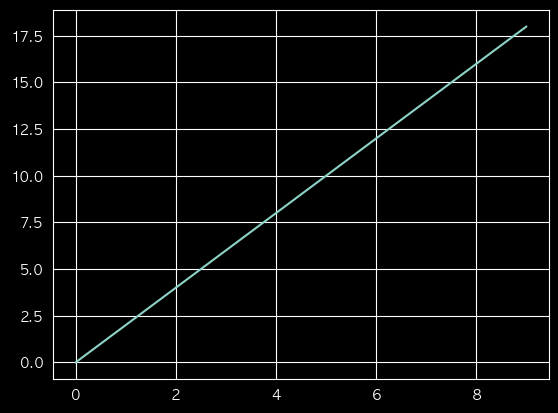

In [86]:
x = range(0,10)
y = [2*value for value in x]
plt.plot(x,y)
plt.show()

#### Code 2-3 개별 데이터 포인트를 표시하는 그래프 그리기

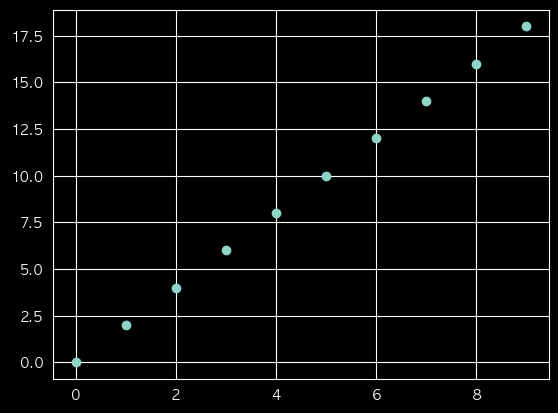

In [87]:
plt.scatter(x,y)
plt.show()

#### Code 2-4 선 그래프 아래 특정 구간을 음영 처리하기

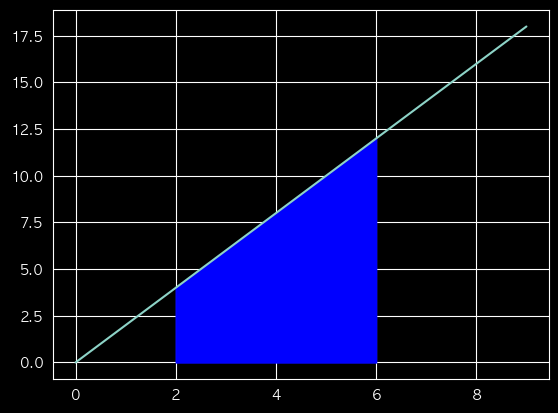

In [88]:
plt.plot(x,y)
where = [is_in_interval(value,2,6) for value in x]
plt.fill_between(x,y,where=where,color = 'blue')
plt.show()

#### Code 2-5 일직선에 개별 데이터 조료 나타내기

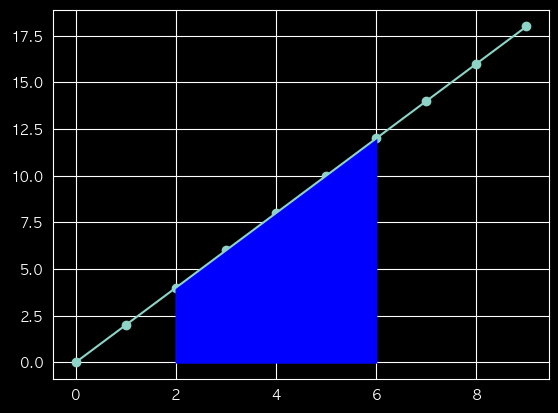

In [89]:
plt.scatter(x,y)
plt.plot(x,y)
where = [is_in_interval(value,2,6) for value in x]
plt.fill_between(x,y,where=where,color = 'blue')
plt.show()

#### Code 2-6 축 레이블링하기

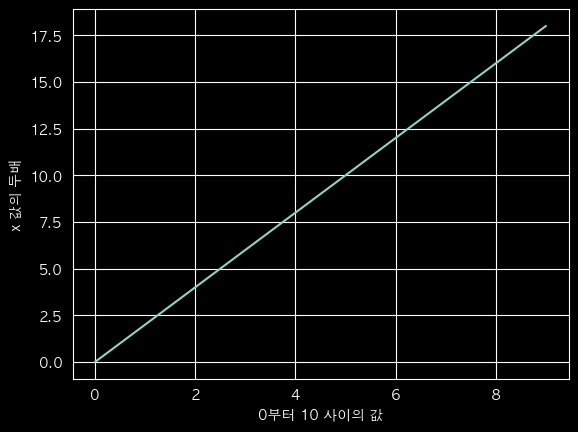

In [90]:
plt.plot(x,y)
plt.xlabel('0부터 10 사이의 값')
plt.ylabel('x 값의 두배')
plt.show()

## 2.2 동전 뒤집기 확률 그래프 그리기

#### Code 2-7 동전 던지기 가중 표본 공간 그리기

x_10_flips : [10, 9, 8, 7, 6, 5, 4, 3, 2, 1, 0]
y_10_flips : [1, 10, 45, 120, 210, 252, 210, 120, 45, 10, 1]


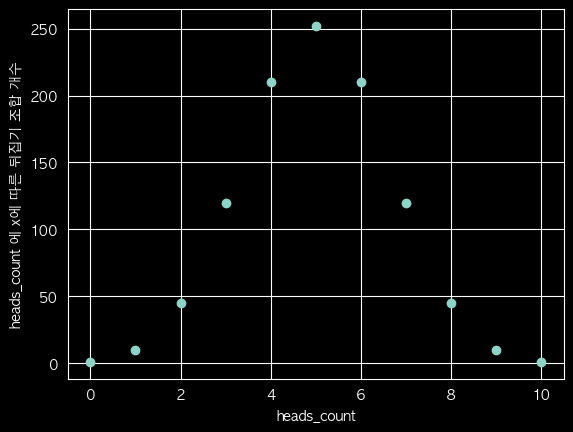

In [91]:
x_10_flips = list(weighted_sample_space.keys())
print(f"x_10_flips : {x_10_flips}")
y_10_flips = [weighted_sample_space[key] for key in x_10_flips]
print(f"y_10_flips : {y_10_flips}")
plt.scatter(x_10_flips, y_10_flips)
plt.xlabel('heads_count')
plt.ylabel('heads_count 에 x에 따른 뒤집기 조합 개수')
plt.show()

#### Code 2-8 동전 뒤집기 확률 그래프

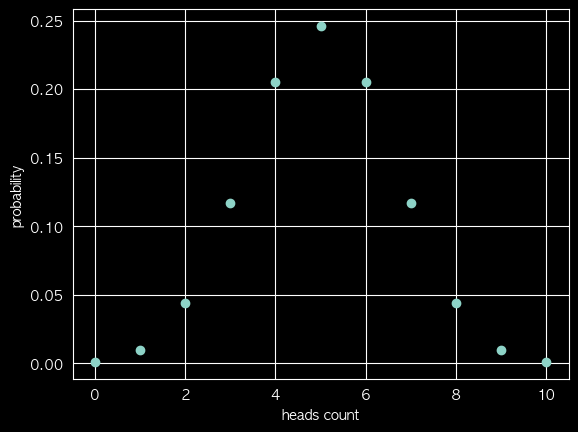

In [92]:
sample_space_size = sum(weighted_sample_space.values())
prob_x_10_flips = [value / sample_space_size for value in y_10_flips]
plt.scatter(x_10_flips, prob_x_10_flips)
plt.xlabel('heads count')
plt.ylabel('probability')
plt.show()

#### Code 2-9 모든 확률을 더하면 1.0이 된다는 것 검증하기

In [93]:
print(prob_x_10_flips, sum(prob_x_10_flips))
# assert sum(prob_x_10_flips) == 1.0

[0.0009765625, 0.009765625, 0.0439453125, 0.1171875, 0.205078125, 0.24609375, 0.205078125, 0.1171875, 0.0439453125, 0.009765625, 0.0009765625] 1.0


#### Code 2-10 확률 곡선 아래의 특정 구간 음영 처리하기

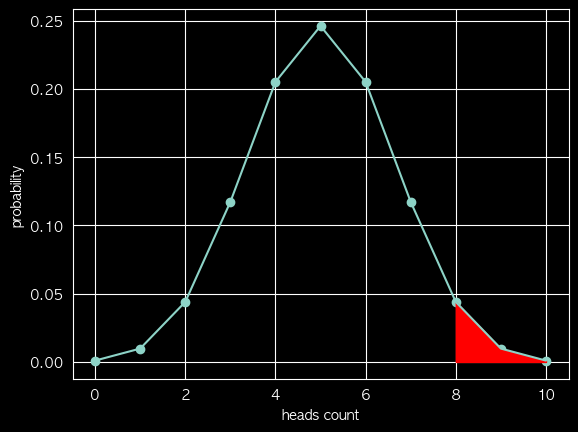

In [94]:
plt.plot(x_10_flips, prob_x_10_flips)
plt.scatter(x_10_flips, prob_x_10_flips)
where = [is_in_interval(value, 8,10) for value in x_10_flips]
plt.fill_between(x_10_flips, prob_x_10_flips, where=where, color='red')
plt.xlabel('heads count')
plt.ylabel('probability')
plt.show()

#### Code 2-11 확률 곡선의 극단적인 구간 음영 처리하기

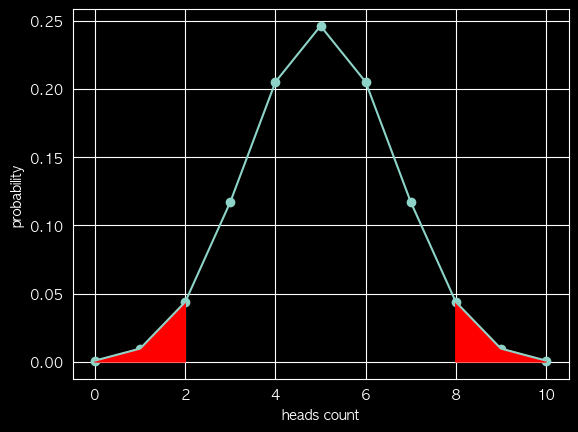

In [95]:
plt.plot(x_10_flips, prob_x_10_flips)
plt.scatter(x_10_flips, prob_x_10_flips)
where = [not is_in_interval(value, 3,7) for value in x_10_flips]
plt.fill_between(x_10_flips, prob_x_10_flips, where=where, color='red')
plt.xlabel('heads count')
plt.ylabel('probability')
plt.show()

### 2.2.1 여럿 동전 뒤집기 확률 분포도 비교하기

#### Code 2-12 동전 뒤집기 분포 20번에 대한 확률 계산하기

In [96]:
x_20_flips = list(weighted_sample_space_20_flips.keys())
y_20_flips = [weighted_sample_space_20_flips[key] for key in x_20_flips]
sample_space_size = sum(weighted_sample_space_20_flips.values())
prob_x_20_flips = [value / sample_space_size for value in y_20_flips]

#### 2-13 동시에 두 분포도 그리기

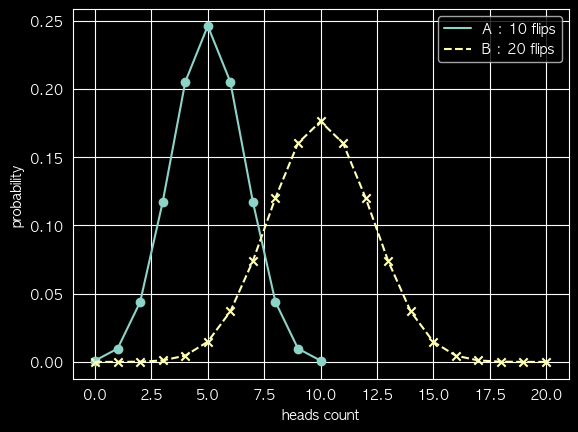

In [97]:
plt.plot(x_10_flips, prob_x_10_flips, label = 'A : 10 flips')
plt.scatter(x_10_flips, prob_x_10_flips)
plt.plot(x_20_flips, prob_x_20_flips, label = 'B : 20 flips', linestyle='--')
plt.scatter(x_20_flips, prob_x_20_flips, marker='x')
plt.xlabel('heads count')
plt.ylabel('probability')
plt.legend()
plt.show()

#### Code 2-14 두 분포의 구간 강조하기

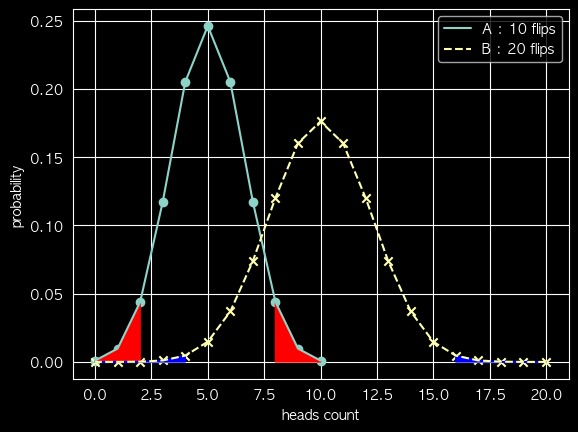

In [98]:
plt.plot(x_10_flips, prob_x_10_flips, label = 'A : 10 flips')
plt.scatter(x_10_flips, prob_x_10_flips)
plt.plot(x_20_flips, prob_x_20_flips, label = 'B : 20 flips', linestyle='--')
plt.scatter(x_20_flips, prob_x_20_flips, marker='x')
where_10 = [not is_in_interval(value,3,7) for value in x_10_flips]
plt.fill_between(x_10_flips, prob_x_10_flips, where=where_10, color='red')
where_20 = [not is_in_interval(value,5,15) for value in x_20_flips]
plt.fill_between(x_20_flips, prob_x_20_flips, where=where_20, color='blue')
plt.xlabel('heads count')
plt.ylabel('probability')
plt.legend()
plt.show()

#### Code 2-15 앞면 갯수를 빈도포 변환하기

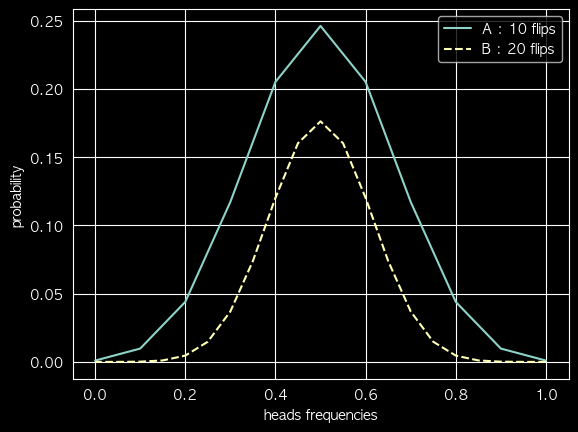

In [99]:
x_10_frequencies = [head_count / 10 for head_count in x_10_flips]
x_20_frequencies = [head_count / 20 for head_count in x_20_flips]
plt.plot(x_10_frequencies, prob_x_10_flips, label = 'A : 10 flips')
plt.plot(x_20_frequencies, prob_x_20_flips, label = 'B : 20 flips', linestyle='--')
plt.legend()
plt.xlabel('heads frequencies')
plt.ylabel('probability')
plt.show()

#### Code 2-16 빈도에 대한 상대적 확률 계산하기

In [100]:
relative_likelihood_10 = [10 * prob for prob in prob_x_10_flips]
relative_likelihood_20 = [20 * prob for prob in prob_x_20_flips]

#### Code 2-17 상대적 확률 곡선 그리기

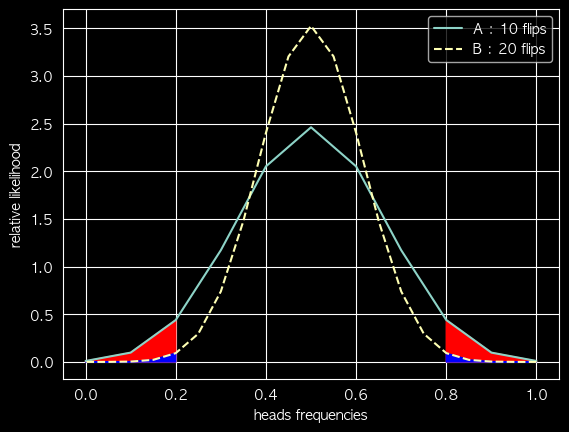

In [101]:
plt.plot(x_10_frequencies, relative_likelihood_10, label = 'A : 10 flips')
plt.plot(x_20_frequencies, relative_likelihood_20, label = 'B : 20 flips', linestyle='--')
plt.legend()
plt.fill_between(x_10_frequencies, relative_likelihood_10, where=where_10, color='red')
plt.fill_between(x_20_frequencies, relative_likelihood_20, where=where_20, color='blue')
plt.xlabel('heads frequencies')
plt.ylabel('relative likelihood')
plt.show()

# 3장 넘파이로 무작위 시뮬레이션 수행하기

## 3.1 넘파이로 무작위 동전 뒤집기와 주사위 던지기 시뮬레이션하기

#### Code 3-2 무작위로 굴린 주사위 시뮬레이션 하기

In [102]:
die_roll = np.random.randint(1,7)
assert 1 <= die_roll <= 6

#### Code 3-3 무작위로 얻은 주사위 값을 재현 가능하도록 시드 설정하기

In [103]:
np.random.seed(0)
die_rolls = [np.random.randint(1,7) for _ in range(3)]
assert die_rolls == [5,6,1]

#### Code 3-4 공정한 동전 뒤집기 한번 시뮬레이션 하기

In [104]:
np.random.seed(0)
coin_flip = np.random.randint(0,2)
print(f"Coin is {'head' if coin_flip == 1 else "tail"}으로 떨어졌습니다")

Coin is tail으로 떨어졌습니다


#### 동전 뒤집기 10번 시뮬레이션하기

In [105]:
np.random.seed(0)
def frequency_heads(coin_flip_sequence):
    total_heads = len([head for head in coin_flip_sequence if head == 1])
    return total_heads / len(coin_flip_sequence)

coin_flips = [np.random.randint(0,2) for _ in range(10)]
print(f"coin_flips : {coin_flips}")
freq_heads = frequency_heads(coin_flips)
print(f"freq_heads : {freq_heads}")
print(f'coin is head 의 관측된 빈도는 {freq_heads}')

coin_flips : [0, 1, 1, 0, 1, 1, 1, 1, 1, 1]
freq_heads : 0.8
coin is head 의 관측된 빈도는 0.8


#### Code 3-6 일련의 공정한 동전 뒤집기 시뮬레이션 그래프

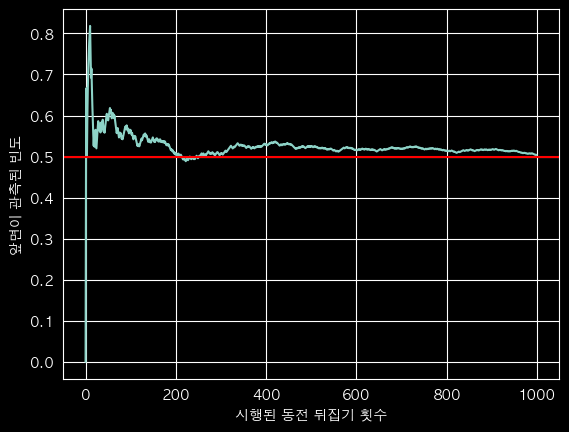

In [106]:
np.random.seed(0)
coin_flips = [ ]
frequencies = [ ]
for _ in range(1000):
    coin_flips.append(np.random.randint(0,2))
    frequencies.append(frequency_heads(coin_flips))

plt.plot(list(range(1000)), frequencies)
plt.axhline(0.5, color = 'red')
plt.xlabel('시행된 동전 뒤집기 횟수')
plt.ylabel('앞면이 관측된 빈도')
plt.show()

#### Code 3-7 편향된 동전 뒤집기 시물레이션하기

In [107]:
np.random.seed(0)
print("동전을 한번 뒤집어 봅니다")
coin_flip = np.random.binomial(1,0.7)
print(f"편향된 동전은 {"heads" if coin_flip == 1 else "tails"}으로 떨어졌습니다")

print("\n동전을 10번 뒤집어 봅니다")
number_coin_flips = 10
head_count = np.random.binomial(number_coin_flips, 0.7)
print(f"{number_coin_flips}번의 편향된 동전 뒤집기 중 앞면은 " f"{head_count}번 관측되었습니다")

동전을 한번 뒤집어 봅니다
편향된 동전은 heads으로 떨어졌습니다

동전을 10번 뒤집어 봅니다
10번의 편향된 동전 뒤집기 중 앞면은 6번 관측되었습니다


#### Code 3-8 동전 뒤집기 빈도의 수렴 정도 계산하기

In [108]:
np.random.seed(0)
head_count = np.random.binomial(1000,0.7)
frequency = head_count / 1000
print(f"Coin is heads 의 probability {frequency} 입니다")

Coin is heads 의 probability 0.697 입니다


#### Code 3-9 동전 뒤집기 빈도의 수렴 정도 계산하기

In [109]:
np.random.seed(0)
assert np.random.binomial(1000,0.7) / 1000 == 0.697
for i in range(1,6):
    head_count = np.random.binomial(1000,0.7)
    frequency = head_count / 1000
    print(f"{i} 번째 반복에서의 빈도는 {frequency} 입니다")
    if frequency == 0.7:
        print("빈도의 실제 확률이 일치합니다\n")

1 번째 반복에서의 빈도는 0.69 입니다
2 번째 반복에서의 빈도는 0.7 입니다
빈도의 실제 확률이 일치합니다

3 번째 반복에서의 빈도는 0.707 입니다
4 번째 반복에서의 빈도는 0.702 입니다
5 번째 반복에서의 빈도는 0.699 입니다


## 3.2 히스토그램과 넘파이 배열로 계산하는 신뢰 구간

#### Code 3-10 동전 뒤집기 샘플링 1,000 번을 500번 수행하는 빈도 계산하기

In [110]:
np.random.seed(0)
head_count_list = [np.random.binomial(1000,0.7) for _ in range(500)]
print(f"heda_count_list : {head_count_list}\n")
print(len(head_count_list))

heda_count_list : [697, 690, 700, 707, 702, 699, 723, 670, 702, 713, 721, 689, 711, 697, 717, 691, 731, 697, 722, 728, 695, 697, 688, 696, 679, 687, 696, 676, 702, 695, 692, 666, 668, 713, 691, 691, 698, 717, 683, 680, 702, 705, 715, 693, 675, 693, 726, 706, 691, 718, 705, 721, 697, 716, 699, 708, 680, 686, 703, 692, 694, 684, 679, 707, 722, 718, 711, 719, 685, 670, 710, 715, 679, 692, 712, 720, 711, 682, 732, 694, 715, 689, 719, 713, 698, 710, 707, 689, 701, 726, 703, 679, 721, 697, 699, 698, 711, 719, 724, 731, 695, 679, 703, 697, 705, 686, 682, 718, 681, 708, 712, 677, 693, 693, 726, 705, 711, 671, 713, 717, 730, 698, 712, 674, 689, 666, 697, 688, 695, 685, 720, 671, 688, 689, 696, 716, 706, 699, 727, 698, 692, 706, 702, 699, 715, 717, 700, 683, 690, 682, 687, 703, 673, 696, 696, 692, 710, 718, 690, 716, 721, 709, 694, 697, 687, 733, 696, 684, 709, 713, 726, 695, 705, 709, 723, 685, 693, 675, 712, 704, 698, 695, 713, 671, 687, 687, 703, 709, 708, 690, 684, 720, 708, 673, 700, 671, 7

#### Code 3-11 동전 뒤집기 빈도 계산 최적화하기

In [111]:
np.random.seed(0)
head_count_array = np.random.binomial(1000,0.7,500)
print(f"heda_count_list : {head_count_array}\n")
print(len(head_count_array))

heda_count_list : [697 690 700 707 702 699 723 670 702 713 721 689 711 697 717 691 731 697
 722 728 695 697 688 696 679 687 696 676 702 695 692 666 668 713 691 691
 698 717 683 680 702 705 715 693 675 693 726 706 691 718 705 721 697 716
 699 708 680 686 703 692 694 684 679 707 722 718 711 719 685 670 710 715
 679 692 712 720 711 682 732 694 715 689 719 713 698 710 707 689 701 726
 703 679 721 697 699 698 711 719 724 731 695 679 703 697 705 686 682 718
 681 708 712 677 693 693 726 705 711 671 713 717 730 698 712 674 689 666
 697 688 695 685 720 671 688 689 696 716 706 699 727 698 692 706 702 699
 715 717 700 683 690 682 687 703 673 696 696 692 710 718 690 716 721 709
 694 697 687 733 696 684 709 713 726 695 705 709 723 685 693 675 712 704
 698 695 713 671 687 687 703 709 708 690 684 720 708 673 700 671 716 692
 723 699 705 695 689 691 705 698 731 705 705 712 709 667 705 679 684 692
 704 697 699 712 686 702 705 694 701 685 719 710 704 708 709 681 694 695
 718 691 688 702 696 722 702 699 

#### Code 3-12 넘파이 배열을 파이썬 리스트로 변환하기

In [112]:
assert head_count_array.tolist() == head_count_list

#### Code 3-13 파이썬 리스트를 넘파이 배열로 변환하기

In [113]:
new_array = np.array(head_count_list)
assert np.array_equal(new_array, head_count_array) == True

#### Code 3-14 넘파이로 빈도 계산하기

In [114]:
frequency_array = head_count_array / 1000
assert frequency_array.tolist() == [head_count / 1000 for head_count in head_count_list]
assert frequency_array.tolist() == list(map(lambda x : x / 1000, head_count_list))

#### Code 3-15 빈도를 담은 넢파이 출력하기

In [115]:
print(frequency_array[:20])

[0.697 0.69  0.7   0.707 0.702 0.699 0.723 0.67  0.702 0.713 0.721 0.689
 0.711 0.697 0.717 0.691 0.731 0.697 0.722 0.728]


#### 3-16 최대 및 최소 빈도값 찾기

In [116]:
min_freq = frequency_array.min()
max_freq = frequency_array.max()
print(f"min_freq : {min_freq}, max_freq : {max_freq}")
print(f"빈도의 범위 : {min_freq} ~ {max_freq} ,range : {max_freq - min_freq}")

min_freq : 0.656, max_freq : 0.733
빈도의 범위 : 0.656 ~ 0.733 ,range : 0.07699999999999996


#### Code 3-17 측정된 빈도 그래프 그리기

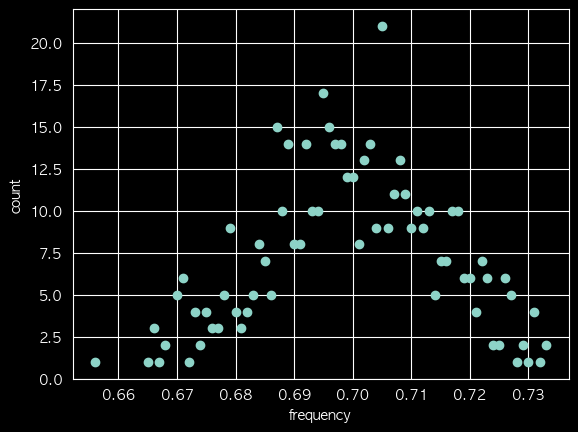

In [117]:
frequency_counts = defaultdict(int)
for frequency in frequency_array:
    frequency_counts[frequency] += 1

frequencies = list(frequency_counts.keys())
counts = [frequency_counts[freq] for freq in frequencies]

plt.scatter(frequencies, counts)
plt.xlabel('frequency')
plt.ylabel('count')
plt.show()

#### Code 3-18 plt.hist 를 사용한 히스토그램 그리기

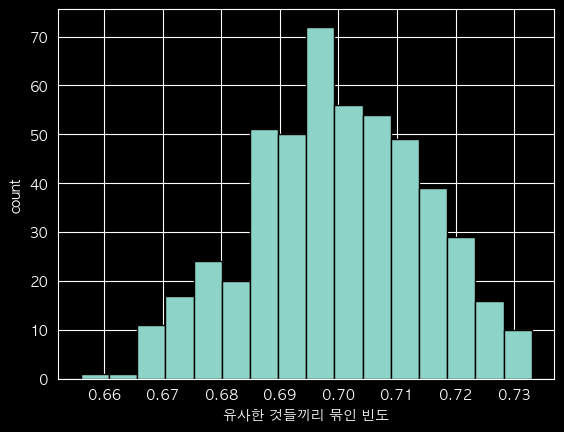

In [118]:
plt.hist(frequency_array, bins ='auto', edgecolor='black')
plt.xlabel('유사한 것들끼리 묶인 빈도')
plt.ylabel('count')
plt.show()

#### Code 3-19 히스토그램 빈 갯수

counts : 16


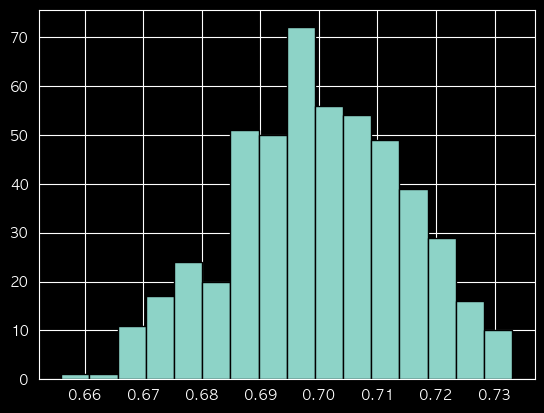

In [119]:
counts, _, _ = plt.hist(frequency_array, bins='auto', edgecolor='black')
print(f"counts : {counts.size}")

#### Code 3-20 히스토그램의 빈 너비 계산하기

빈 너비 : 0.004812499999999997


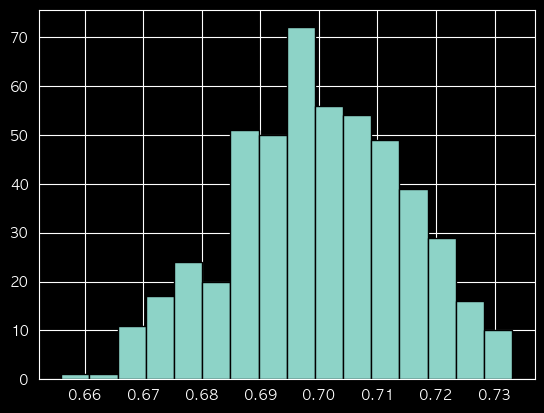

In [127]:
counts, bin_edges,_ = plt.hist(frequency_array, bins='auto', edgecolor='black')
bin_width = bin_edges[1] - bin_edges[0]
assert bin_width == (max_freq - min_freq) / counts.size
print(f"빈 너비 : {bin_width}")

##### Code 3-21 빈의 빈도와 크기

In [128]:
def output_bin_coverage(i):
    count = int(counts[i])
    range_start, range_end = bin_edges[i], bin_edges[i+1]
    range_string = f"{range_start:.4f} ~ {range_end:.4f}"
    print(f"빈도의 범위 : {range_string}에 대한 빈은 "
          f"{count} 개의 요소를 포함합니다")

output_bin_coverage(0)
output_bin_coverage(5)

빈도의 범위 : 0.6560 ~ 0.6608에 대한 빈은 1 개의 요소를 포함합니다
빈도의 범위 : 0.6801 ~ 0.6849에 대한 빈은 20 개의 요소를 포함합니다


#### Code 3-22 배열의 최대값에 대한 인덱스 구하기

In [129]:
assert counts[counts.argmax()] == counts.max()

#### Code 3-23 히스토그램의 가장 높은 구간을 반환하는 데 argmax 사용하기

In [124]:
output_bin_coverage(counts.argmax())

빈도의 범위 : 0.6945 ~ 0.6993에 대한 빈은 72 개의 요소를 포함합니다


### 3.2.2 히스토그램에서 확률 구하기

#### Code 3-24 히스토그램의 상대적 확률 그리기

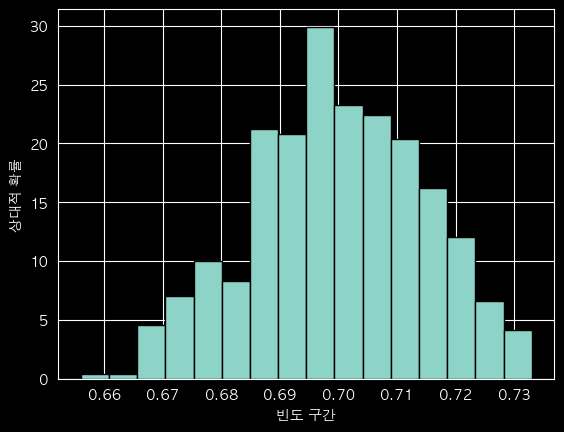

In [130]:
likelihoods, bin_edges , _ = plt.hist(
    frequency_array, bins='auto', edgecolor='black', density=True)
plt.xlabel('빈도 구간')
plt.ylabel('상대적 확률')
plt.show()

##### Code 3-25 히스토그램의 전체 영역 계산하기

In [131]:
assert likelihoods.sum() * bin_width == 1.0

In [132]:
index = likelihoods.argmax()
print(index)
area = likelihoods[index] * bin_width
print(area)
range_start, range_end = bin_edges[index] , bin_edges[index+1]
range_string = f"{range_start} - {range_end}"
print(f"샘플링된 빈도가 {range_string} 구간에 속한 확률은 {area} 입니다")

8
0.144
샘플링된 빈도가 0.6945 - 0.6993125 구간에 속한 확률은 0.144 입니다


##### Code 3-27 빈도 범위를 확률 늘리기

In [133]:
peak_index = likelihoods.argmax()
start_index, end_index = (peak_index - 1, peak_index + 2)
area = likelihoods[start_index:end_index].sum() * bin_width
print(start_index, end_index, area)
range_string = f"{start_index} - {end_index}"
print(f"샘플링된 빈도가 {range_string} 구간에 속할 활률은 {area} 입니다")

7 10 0.35600000000000004
샘플링된 빈도가 7 - 10 구간에 속할 활률은 0.35600000000000004 입니다


##### Code 3-28 높은 신뢰 구간 계산하기

In [134]:
def compute_high_confidence_interval(likelihoods, bin_width):
    peak_index = likelihoods.argmax()
    area = likelihoods[peak_index] * bin_width
    start_index, end_index = (peak_index , peak_index + 1)
    while area < 0.95:
        if start_index > 0:
            start_index -= 1
        if end_index < len(likelihoods) - 1:
            end_index += 1

        area = likelihoods[start_index:end_index+1].sum() * bin_width

    range_start , range_end = bin_edges[start_index], bin_edges[end_index]
    range_string = f"{range_start:.6f} - {end_index:.6f}"
    print(f" 빈도 범위 {range_start} 는 {100 * area:.2f}% 신뢰 구간을 나타냅니다")
    return start_index, end_index

compute_high_confidence_interval(likelihoods, bin_width)

 빈도 범위 0.6704375 는 95.40% 신뢰 구간을 나타냅니다


(np.int64(3), np.int64(14))

#### 3.2.3 괴신뢰 구간의 범위 줄이기

##### Code 3-29 빈도 10만 개 샘플링하기

In [135]:
np.random.seed(0)
head_count_array = np.random.binomial(1000,0.7,100000)
frequency_array = head_count_array / 1000
assert frequency_array.size == 100000

##### 3-30 특정 구간에 대해 히스토그램 막대 색칠하기

 빈도 범위 0.6704285714285715 는 95.42% 신뢰 구간을 나타냅니다


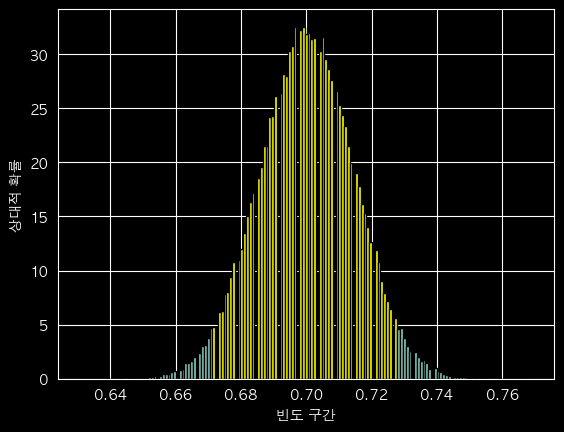

In [136]:
likelihoods, bin_edges, patches = plt.hist(
    frequency_array, bins='auto', edgecolor='black', density=True)
bin_width = bin_edges[1] - bin_edges[0]
start_index, end_index = compute_high_confidence_interval(likelihoods, bin_width)

for i in range(start_index, end_index):
    patches[i].set_facecolor('yellow')
plt.xlabel('빈도 구간')
plt.ylabel('상대적 확률')
plt.show()

##### 동전 뒤집기를 50억번 실행하기

 빈도 범위 0.6957690566037736 는 95.06% 신뢰 구간을 나타냅니다


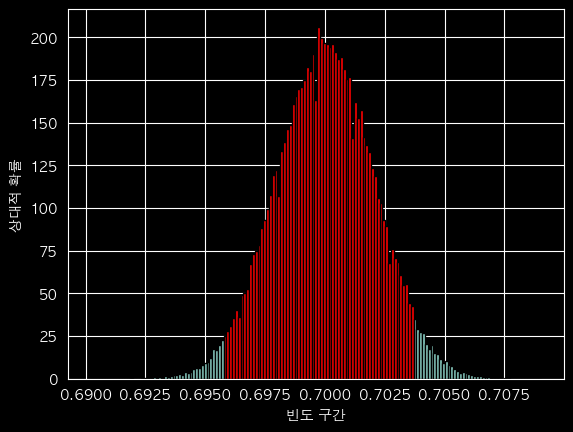

In [137]:
np.random.seed(0)
head_count_array = np.random.binomial(50000,0.7,100000)
frequency_array = head_count_array / 50000

likelihoods, bin_edges, patches = plt.hist(
    frequency_array, bins='auto', edgecolor='black', density=True)
bin_width = bin_edges[1] - bin_edges[0]
start_index, end_index = compute_high_confidence_interval(likelihoods, bin_width)

for i in range(start_index, end_index):
    patches[i].set_facecolor('red')
plt.xlabel('빈도 구간')
plt.ylabel('상대적 확률')
plt.show()

#### 3.2.4 넘파이로 히스토그램 계산하기